# CA6003 Bank Marketing · A+C+D 整合草稿

更新：2026-10-16。**B的核心发现未收到，最终测试未执行，本文件尚不是完整课程提交物。**

A提供数据治理与固定划分；C提供正式S/U管线和转换测试；LIANG SHUANG（D）负责评价与本次接入。C原增量ZIP不含说明提到的analysis.ipynb，本文件由已有真实材料重建，并不声称由C原包提供。B位置明确留空。核心A审计、C转换、D评价函数已内嵌，数据与证据文件随交付包提供。

In [1]:
from pathlib import Path
import sys, json, platform
ROOT = Path.cwd()
if not (ROOT / 'data/raw/bank-full.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw/bank-full.csv').exists(), 'Run from repository root or notebooks/'
import sklearn, pandas as pd, numpy as np
print({'python': platform.python_version(), 'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__})

{'python': '3.12.14', 'sklearn': '1.8.0', 'pandas': '3.0.6', 'numpy': '2.5.4'}


In [2]:
from IPython.display import display

## 01–02 / A：数据来源、范围和治理

In [3]:
"""Frozen data contract shared by A/B/C/D. No learned transformations."""

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

LOCK = json.loads((ROOT / "config/dataset_lock.json").read_text(encoding="utf-8"))
EXPECTED_COLUMNS = LOCK["columns"]
FEATURES = LOCK["allowed_features"]
EXCLUDED = LOCK["excluded_features"]
NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
CATEGORIES = {
    "job": ["admin.", "unknown", "unemployed", "management", "housemaid", "entrepreneur", "student", "blue-collar", "self-employed", "retired", "technician", "services"],
    "marital": ["married", "divorced", "single"],
    "education": ["unknown", "secondary", "primary", "tertiary"],
    "default": ["yes", "no"], "housing": ["yes", "no"], "loan": ["yes", "no"],
    "contact": ["unknown", "telephone", "cellular"],
    "month": ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    "poutcome": ["unknown", "other", "failure", "success"], "y": ["yes", "no"],
}


def sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def verify_bytes(data: bytes, expected: dict, label: str) -> None:
    if sha256_bytes(data) != expected["sha256"]:
        raise ValueError(f"SHA-256 mismatch: {label}. Do not repair or overwrite the raw file.")
    if "bytes" in expected and len(data) != expected["bytes"]:
        raise ValueError(f"Byte length mismatch: {label}")


def read_raw(root: Path = ROOT) -> pd.DataFrame:
    path = root / "data/raw/bank-full.csv"
    verify_bytes(path.read_bytes(), LOCK["artifacts"]["data/raw/bank-full.csv"], str(path.name))
    raw = pd.read_csv(path, sep=";", keep_default_na=False)
    if list(raw.columns) != EXPECTED_COLUMNS or raw.shape != (45211, 17):
        raise ValueError("Unexpected CSV version, columns, or shape")
    for column in NUMERIC:
        if not pd.api.types.is_integer_dtype(raw[column]):
            raise ValueError(f"Expected integer dtype: {column}")
    for column, allowed in CATEGORIES.items():
        if not raw[column].isin(allowed).all():
            raise ValueError(f"Unexpected category: {column}")
    if raw.isna().any().any() or raw.astype(str).apply(lambda s: s.str.strip().eq("")).any().any():
        raise ValueError("Unexpected actual missing/empty cell")
    raw.index.name = "row_id"  # Original zero-based data-record position, not CSV line number.
    return raw


def make_splits(raw: pd.DataFrame) -> dict[str, np.ndarray]:
    y = raw["y"].map({"no": 0, "yes": 1})
    if y.isna().any():
        raise ValueError("Unexpected target value")
    ids = np.arange(len(raw))
    dev, test = train_test_split(ids, test_size=.20, stratify=y, random_state=42)
    train, val = train_test_split(dev, test_size=.25, stratify=y.iloc[dev], random_state=42)
    return {"train": train, "val": val, "test": test}


def make_manifest(raw: pd.DataFrame, splits: dict[str, np.ndarray]) -> pd.DataFrame:
    assignment = pd.Series("", index=np.arange(len(raw)), name="split")
    for name, ids in splits.items():
        assignment.loc[ids] = name
    result = assignment.rename_axis("row_id").reset_index()
    all_ids = np.concatenate(list(splits.values()))
    if len(all_ids) != len(raw) or len(np.unique(all_ids)) != len(raw):
        raise ValueError("Splits overlap or fail complete coverage")
    if not np.array_equal(np.sort(all_ids), np.arange(len(raw))) or assignment.eq("").any():
        raise ValueError("Invalid split row ids")
    return result


def load_split_indices(root: Path = ROOT) -> dict[str, np.ndarray]:
    saved = json.loads((root / "data/splits/split_indices.json").read_text(encoding="utf-8"))
    if not isinstance(saved, dict) or set(saved) != {"train", "val", "test"}:
        raise ValueError("Unexpected split names")
    for name, ids in saved.items():
        if not isinstance(ids, list) or any(type(value) is not int for value in ids):
            raise ValueError(f"Split {name} row ids must be plain JSON integers; no strings, floats or booleans")
        if any(value < 0 or value >= LOCK["shape"][0] for value in ids):
            raise ValueError(f"Split {name} row id outside original row range")
    return {name: np.asarray(ids, dtype=np.int64) for name, ids in saved.items()}


def validate_saved_splits(raw: pd.DataFrame, root: Path = ROOT) -> dict[str, np.ndarray]:
    expected = make_splits(raw)
    saved = load_split_indices(root)
    for name in expected:
        if not np.array_equal(saved[name], expected[name]):
            raise ValueError(f"Frozen split changed: {name}")
    manifest = pd.read_csv(root / "data/splits/split_manifest.csv", keep_default_na=False)
    pd.testing.assert_frame_equal(manifest, make_manifest(raw, expected))
    return saved


def load_partition(name: str, *, allow_test: bool = False, root: Path = ROOT):
    """Return X (11 original columns), integer y, with aligned row_id indices.

    The flag is a workflow guard, not access control: raw data remain available.
    C/D must preserve this row order and fit learned transforms only on training.
    """
    if name not in {"train", "val", "test"}:
        raise ValueError("Expected train, val, or test")
    if name == "test" and not allow_test:
        raise ValueError("Test is sealed until protocol freeze; D must explicitly allow_test=True")
    raw = read_raw(root)
    splits = validate_saved_splits(raw, root)
    frame = raw.loc[splits[name]]
    X = frame.loc[:, FEATURES].copy()
    y = frame["y"].map({"no": 0, "yes": 1}).astype("int64")
    if not X.index.equals(y.index) or list(X.columns) != FEATURES:
        raise ValueError("Broken model-input contract")
    return X, y


## 1. Provenance, license and scope

仅使用 legacy `bank-full.csv`：45,211 行、16 个原始输入 + y。外 ZIP → bank.zip → 原始 CSV/说明。拒绝 bank-additional、bank.csv 抽样版和更改列名/分隔符的 data.csv。

来源：[UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)，许可：[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)。数据作者 Moro、Rita、Cortez；数据引用 DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306)。旧版说明另要求引用 Moro、Laureano、Cortez (2011)，详见仓库 THIRD_PARTY_NOTICES.md。

原始字节不修改；row_id、划分及审计是本项目增加的派生成果。署名不表示作者或 UCI 背书。

在仓库根目录或 notebooks/ 下打开本章。所有路径相对项目，不下载个人资料。若尚未准备数据，先运行 `python scripts/prepare_data.py`。

In [4]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
ROOT = Path.cwd().resolve()
if not (ROOT / 'config/dataset_lock.json').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'config/dataset_lock.json').is_file(), 'Open from repository root or notebooks/'
sys.path.insert(0, str(ROOT))
lock = json.loads((ROOT / 'config/dataset_lock.json').read_text(encoding='utf-8'))
for relative, expected in lock['artifacts'].items():
    data = (ROOT / relative).read_bytes()
    assert hashlib.sha256(data).hexdigest() == expected['sha256'], relative
    assert 'bytes' not in expected or len(data) == expected['bytes'], relative
provenance = json.loads((ROOT / 'data/source/provenance.json').read_text(encoding='utf-8'))
print('Acquired UTC:', provenance['acquired_utc'])
print('Raw SHA-256:', lock['artifacts']['data/raw/bank-full.csv']['sha256'])
print('All four pinned source artifacts verified')

Acquired UTC: 2026-10-12T09:30:28.154035+00:00
Raw SHA-256: d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d
All four pinned source artifacts verified


## 2. Read without semantic cleaning and freeze the exact split

`keep_default_na=False` 保留文字 unknown 和原空字符串；显式空值由审计单独检查。`row_id=np.arange(len(raw))` 对应原始数据行的 0-based 位置，不是客户标识，也不进入 X。两次 stratified split 严格使用 random_state=42；第二次必须使用 y.iloc[dev]。Manifest 按原始 row_id 排序，JSON 另保留 split 返回顺序。

In [5]:
raw = pd.read_csv(ROOT / 'data/raw/bank-full.csv', sep=';', keep_default_na=False)
assert list(raw.columns) == lock['columns'] and raw.shape == (45211, 17)
y = raw['y'].map({'no': 0, 'yes': 1})
assert not y.isna().any()
ids = np.arange(len(raw))
dev, test = train_test_split(ids, test_size=.20, stratify=y, random_state=42)
train, val = train_test_split(dev, test_size=.25, stratify=y.iloc[dev], random_state=42)
splits = {'train': train, 'val': val, 'test': test}
assert len(set(train) & set(val)) == 0
assert len(set(dev) & set(test)) == 0
assert set(np.concatenate(list(splits.values()))) == set(ids)
assignment = pd.Series('', index=ids, name='split')
for name, positions in splits.items():
    assignment.loc[positions] = name
manifest = assignment.rename_axis('row_id').reset_index()
pd.testing.assert_frame_equal(manifest, pd.read_csv(ROOT / 'data/splits/split_manifest.csv'))
saved = json.loads((ROOT / 'data/splits/split_indices.json').read_text(encoding='utf-8'))
assert all(np.array_equal(splits[name], saved[name]) for name in splits)
raw.index.name = 'row_id'
print('Shape:', raw.shape, 'split sizes:', {k: len(v) for k,v in splits.items()})

Shape: (45211, 17) split sizes: {'train': 27126, 'val': 9042, 'test': 9043}


以下表仅对 train 展示标签分布；val/test 只显示预定行数覆盖信息，其标签统计保持空白。开放 profiling 仅使用 train。封存是团队流程约束，原始 CSV 本身仍包含全部记录。

In [6]:
display(pd.read_csv(ROOT / 'outputs/split_summary.csv'))
format_checks = pd.read_csv(ROOT / 'outputs/format_checks.csv')
assert format_checks.n_violations.sum() == 0
print('Predeclared holdout format checks passed:', len(format_checks))

,partition,n_rows,n_no,n_yes,positive_rate,purpose
0,train,27126,23953.0,3173.0,0.116973,training profile
1,val,9042,NaN,NaN,NaN,structure/coverage only; label statistics with...
2,test,9043,NaN,NaN,NaN,structure/coverage only; label statistics with...


Predeclared holdout format checks passed: 78


## 3. Dictionary and prediction-time policy

11 个输入：age、job、marital、education、default、balance、housing、loan、pdays、previous、poutcome。

duration 是通话后信息；campaign、contact、day、month 也按保守的联系前时点排除。这是小组研究设计，而非 UCI 或课程强制限制。reviewer 保留 pending，待真实成员复核。

In [7]:
dictionary = pd.read_csv(ROOT / 'notes/data_dictionary.csv', keep_default_na=False)
policy = pd.read_csv(ROOT / 'notes/feature_policy.csv', keep_default_na=False)
assert dictionary.field.tolist() == lock['columns']
allowed = policy.loc[policy.role.eq('input'), 'field'].tolist()
assert allowed == lock['allowed_features']
assert not set(allowed) & {'y', 'row_id', 'duration', 'campaign', 'contact', 'day', 'month'}
display(dictionary)
display(policy[['field', 'role', 'prediction_time', 'reviewer']])

,field,storage_type,meaning,unit,documented_categories,special_semantics,role,source
0,age,integer,Client age,years,,Positive integer; no arbitrary age trimming,input,data/raw/bank-names.txt; UCI dataset 222
1,job,string,Type of job,category,admin.|unknown|unemployed|management|housemaid...,unknown is a literal category; U applies here,input,data/raw/bank-names.txt; UCI dataset 222
2,marital,string,Marital status,category,married|divorced|single,divorced includes divorced or widowed in the s...,input,data/raw/bank-names.txt; UCI dataset 222
3,education,string,Education category,category,unknown|secondary|primary|tertiary,Legacy primary/secondary/tertiary/unknown; U a...,input,data/raw/bank-names.txt; UCI dataset 222
4,default,string,Has credit in default?,yes/no,yes|no,Do not infer default amount or date,input,data/raw/bank-names.txt; UCI dataset 222
5,balance,integer,Average yearly balance,EUR,,Negative and extreme values are not automatica...,input,data/raw/bank-names.txt; UCI dataset 222
6,housing,string,Has housing loan?,yes/no,yes|no,Retain original categories,input,data/raw/bank-names.txt; UCI dataset 222
7,loan,string,Has personal loan?,yes/no,yes|no,Retain original categories,input,data/raw/bank-names.txt; UCI dataset 222
8,contact,string,Last contact communication type,category,unknown|telephone|cellular,Current campaign contact process; excluded,excluded,data/raw/bank-names.txt; UCI dataset 222
9,day,integer,Day of month of last contact,1-31,,Not day_of_week; incomplete calendar information,excluded,data/raw/bank-names.txt; UCI dataset 222


,field,role,prediction_time,reviewer
0,age,input,Assumed available before current campaign cont...,pending
1,job,input,Assumed available before current campaign cont...,pending
2,marital,input,Assumed available before current campaign cont...,pending
3,education,input,Assumed available before current campaign cont...,pending
4,default,input,Assumed available before current campaign cont...,pending
5,balance,input,Assumed available before current campaign cont...,pending
6,housing,input,Assumed available before current campaign cont...,pending
7,loan,input,Assumed available before current campaign cont...,pending
8,contact,excluded,Current/last-contact or campaign process; cons...,pending
9,day,excluded,Current/last-contact or campaign process; cons...,pending


## 4. Training-only quality evidence

本单元使用仓库内 `src/audit.py` 的审计函数（随本章一起提交，非个人外部脚本）。C 总装最终单一提交 Notebook 时，应将所需函数内联或按课程允许方式打包。

区分 NaN/空串、unknown、pdays=-1。pdays=-1 是此前未联系；pdays=0 是实际间隔。负余额、高联系次数、匹配记录不自动等于错误。STOP 级规则只有 n_affected>0 才阻塞；INVESTIGATE 表示待人工调查，不执行删除。

In [8]:
"""Descriptive data-quality evidence. Open profiling is restricted to train."""

import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn


# Data-contract names are defined above; core audit source included here.

AUDIT_COLUMNS = ["check_id", "field", "rule", "partition", "n_affected", "example_row_ids",
                 "severity", "decision", "rationale", "owner"]


def format_checks(frame: pd.DataFrame, partition: str) -> list[dict]:
    """Rules specified before inspection; holdout checks contain no open profiling."""
    checks = []
    def add(rule, n):
        checks.append({"partition": partition, "rule": rule, "n_violations": int(n), "passed": int(n) == 0})
    add("exact_17_columns_in_source_order", int(list(frame.columns) != EXPECTED_COLUMNS))
    add("no_actual_null_cells", frame.isna().sum().sum())
    add("no_empty_or_whitespace_cells", frame.astype(str).apply(lambda s: s.str.strip().eq("")).sum().sum())
    for column in NUMERIC:
        add(f"{column}:integer_dtype", int(not pd.api.types.is_integer_dtype(frame[column])))
    for column, values in CATEGORIES.items():
        add(f"{column}:documented_category", (~frame[column].isin(values)).sum())
    for name, mask in {
        "age:positive": frame.age.le(0), "day:1_to_31": ~frame.day.between(1, 31),
        "duration:nonnegative": frame.duration.lt(0), "campaign:at_least_one": frame.campaign.lt(1),
        "pdays:minus_one_or_nonnegative": frame.pdays.lt(-1), "previous:nonnegative": frame.previous.lt(0),
    }.items():
        add(name, mask.sum())
    return checks


def profile_train(train: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name in EXPECTED_COLUMNS:
        col = train[name]
        text = col.astype(str)
        item = {"partition": "train", "field": name, "dtype": str(col.dtype), "n_rows": len(col),
                "n_null": int(col.isna().sum()), "n_empty": int(text.eq("").sum()),
                "n_whitespace_only": int((text.str.strip().eq("") & text.ne("")).sum()),
                "n_unknown": int(text.eq("unknown").sum()), "n_minus_one": int(text.eq("-1").sum()),
                "n_unique": int(col.nunique(dropna=False))}
        if name in NUMERIC:
            for label, q in [("min", 0), ("q01", .01), ("q25", .25), ("median", .5), ("q75", .75), ("q99", .99), ("max", 1)]:
                item[label] = float(col.quantile(q))
        rows.append(item)
    return pd.DataFrame(rows)


def audit_train(train: pd.DataFrame) -> pd.DataFrame:
    rows = []
    def add(check_id, field, rule, mask, severity, decision, rationale, owner="A"):
        selected = train.index[np.asarray(mask, dtype=bool)]
        rows.append(dict(zip(AUDIT_COLUMNS, [check_id, field, rule, "train", len(selected),
                    json.dumps([int(x) for x in selected[:5]]), severity, decision, rationale, owner])))
    for name in EXPECTED_COLUMNS:
        values = train[name]
        missing = values.isna() | values.astype(str).str.strip().eq("")
        add("missing_" + name, name, "actual null or empty/whitespace cell", missing, "STOP",
            "Stop if affected; otherwise pass", "Unexpected actual missingness requires source/parse review; no automatic imputation")
        if name in CATEGORIES:
            add("category_" + name, name, "value outside documented bank-names categories", ~values.isin(CATEGORIES[name]), "STOP",
                "Stop if affected; otherwise pass", "Version/format mismatch must be resolved without recoding records")
        unknown = values.astype(str).eq("unknown")
        if "unknown" in CATEGORIES.get(name, []):
            add("unknown_" + name, name, "literal category unknown", unknown, "VALID_STATE", "Retain raw category",
                "Literal unknown is not NaN; C may compare job/education strategies only; poutcome stays unchanged", "A; C implementation pending")
    for name, mask in {
        "age": train.age.le(0), "day": ~train.day.between(1, 31), "duration": train.duration.lt(0),
        "campaign": train.campaign.lt(1), "pdays": train.pdays.lt(-1), "previous": train.previous.lt(0),
    }.items():
        add("domain_" + name, name, "violates predeclared integer domain", mask, "STOP",
            "Stop if affected; otherwise pass", "Verify raw provenance and documentation before any repair")
    add("pdays_never", "pdays", "pdays == -1", train.pdays.eq(-1), "VALID_STATE", "Retain sentinel in raw",
        "Never contacted in a previous campaign; not missing days; S is implemented by C")
    add("pdays_zero", "pdays", "pdays == 0", train.pdays.eq(0), "VALID_STATE", "Retain distinct from -1",
        "Zero elapsed days is a nonnegative interval; it must not mean never contacted")
    add("negative_balance", "balance", "balance < 0", train.balance.lt(0), "VALID_STATE", "Retain negative balance",
        "Average annual balance in EUR can be negative; no evidence of parsing error")
    for name in ["balance", "previous"]:
        cut = float(train[name].quantile(.99))
        add("upper_tail_" + name, name, f"value > training 99th percentile ({cut:g})", train[name].gt(cut), "INVESTIGATE",
            "Retain; B reviews tail evidence", "A descriptive training-only flag, not an invalidity boundary or deletion rule", "A; B review pending")
    never = train.pdays.eq(-1)
    zero_prev = train.previous.eq(0)
    add("history_never_positive_previous", "pdays,previous", "pdays == -1 and previous > 0", never & ~zero_prev, "INVESTIGATE",
        "Retain; review any affected rows", "Different campaign-history definitions may explain a mismatch; do not fabricate contact history", "A; B/C review pending")
    add("history_contacted_zero_previous", "pdays,previous", "pdays >= 0 and previous == 0", ~never & zero_prev, "INVESTIGATE",
        "Retain; review any affected rows", "A semantic consistency check; not grounds for automatic deletion", "A; B/C review pending")
    add("history_contacted_unknown_outcome", "pdays,poutcome", "pdays >= 0 and poutcome == unknown", ~never & train.poutcome.eq("unknown"), "INVESTIGATE",
        "Retain unknown outcome", "Unknown outcome cannot automatically be interpreted as no previous contact", "A; B/C review pending")
    add("history_never_known_outcome", "pdays,poutcome", "pdays == -1 and poutcome != unknown", never & train.poutcome.ne("unknown"), "INVESTIGATE",
        "Retain; verify meaning", "A known outcome alongside never-contacted requires review rather than invented replacement", "A; B/C review pending")
    add("duplicate_full_rows", "all 17 raw fields", "all members of exact duplicate groups (keep=False)", train.duplicated(keep=False), "INVESTIGATE",
        "Retain all rows", "Matching public records do not establish duplicate people; row_id is not customer ID")
    for scope, features in [("raw16", EXPECTED_COLUMNS[:-1]), ("allowed11", FEATURES)]:
        n_labels = train.groupby(features, dropna=False, sort=False)["y"].transform("nunique")
        add("conflicting_labels_" + scope, ",".join(features), "same feature values with more than one target label; affected group members", n_labels.gt(1), "INVESTIGATE",
            "Retain; document identifiability limitation", "Feature equality is not identity; do not merge clients or choose a preferred label")
    return pd.DataFrame(rows, columns=AUDIT_COLUMNS)


def write_reports(raw: pd.DataFrame, splits: dict[str, np.ndarray], root: Path = ROOT) -> dict:
    out = root / "outputs"
    out.mkdir(parents=True, exist_ok=True)
    train = raw.loc[np.sort(splits["train"])]
    profile = profile_train(train)
    audit = audit_train(train)
    profile.to_csv(out / "train_profile.csv", index=False, lineterminator="\n")
    audit.to_csv(out / "quality_audit.csv", index=False, lineterminator="\n")
    formats = pd.DataFrame([check for name, ids in splits.items() for check in format_checks(raw.loc[ids], name)])
    formats.to_csv(out / "format_checks.csv", index=False, lineterminator="\n")
    split_summary = []
    for name, ids in splits.items():
        targets = raw.loc[ids, "y"] if name == "train" else None
        split_summary.append({"partition": name, "n_rows": len(ids),
                              "n_no": int(targets.eq("no").sum()) if targets is not None else None,
                              "n_yes": int(targets.eq("yes").sum()) if targets is not None else None,
                              "positive_rate": float(targets.eq("yes").mean()) if targets is not None else None,
                              "purpose": "training profile" if name == "train" else "structure/coverage only; label statistics withheld"})
    pd.DataFrame(split_summary).to_csv(out / "split_summary.csv", index=False, lineterminator="\n")
    history = train.assign(pdays_state=np.where(train.pdays.eq(-1), "never_-1", "contacted_ge0"),
                           previous_state=np.where(train.previous.eq(0), "zero", "positive"))
    counts = history.groupby(["pdays_state", "previous_state", "poutcome"], dropna=False).size().rename("n").reset_index()
    counts.insert(0, "partition", "train")
    counts["denominator"] = len(train)
    counts.to_csv(out / "train_history_consistency.csv", index=False, lineterminator="\n")
    summary = {
        "raw_shape": list(raw.shape), "split_sizes": {name: len(ids) for name, ids in splits.items()},
        "open_profile_partition": "train", "training_rows": len(train),
        "holdout_policy": "predeclared schema, category membership, numeric domain and row coverage checks only; no holdout label statistics",
        "format_violations": int(formats.n_violations.sum()),
        "audit_stop_affected": int(audit.loc[audit.severity.eq("STOP"), "n_affected"].sum()),
        "training_exact_duplicate_group_members": int(train.duplicated(keep=False).sum()),
        "training_duplicate_excess_rows": int(train.duplicated(keep="first").sum()),
        "training_pdays_minus_one": int(train.pdays.eq(-1).sum()),
        "training_pdays_zero": int(train.pdays.eq(0).sum()),
        "training_unknown_job": int(train.job.eq("unknown").sum()),
        "training_unknown_education": int(train.education.eq("unknown").sum()),
        "training_negative_balance": int(train.balance.lt(0).sum()),
        "rows_deleted": 0, "imputation_fitted": False, "scaler_fitted": False, "models_fitted": 0,
        "student_review": "pending", "C_semantic_review": "pending",
    }
    (out / "audit_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8", newline="\n")
    environment = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                   "scikit-learn": sklearn.__version__, "platform": platform.system(), "machine": platform.machine()}
    (out / "environment.json").write_text(json.dumps(environment, indent=2) + "\n", encoding="utf-8", newline="\n")
    if summary["format_violations"] or summary["audit_stop_affected"]:
        raise ValueError("Blocking data-quality failure; inspect saved audit, do not clean silently")
    return summary


In [9]:

training = raw.loc[np.sort(train)].copy()
profile = profile_train(training)
audit = audit_train(training)
saved_audit = pd.read_csv(ROOT / 'outputs/quality_audit.csv', keep_default_na=False)
pd.testing.assert_frame_equal(audit, saved_audit)
assert audit.partition.eq('train').all()
assert audit.loc[audit.severity.eq('STOP'), 'n_affected'].sum() == 0
display(profile)
display(audit.loc[audit.n_affected.gt(0), ['check_id','field','n_affected','example_row_ids','severity','decision']])
print('No source rows dropped. No imputer/scaler/model fitted.')

,partition,field,dtype,n_rows,n_null,n_empty,n_whitespace_only,n_unknown,n_minus_one,n_unique,min,q01,q25,median,q75,q99,max
0,train,age,int64,27126,0,0,0,0,0,76,18.0,23.0,33.0,39.0,48.00,71.00,95.0
1,train,job,str,27126,0,0,0,179,0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,train,marital,str,27126,0,0,0,0,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,train,education,str,27126,0,0,0,1100,0,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,train,default,str,27126,0,0,0,0,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,train,balance,int64,27126,0,0,0,0,24,5896,-6847.0,-627.0,73.0,454.0,1425.75,13146.25,81204.0
6,train,housing,str,27126,0,0,0,0,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,train,loan,str,27126,0,0,0,0,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,train,contact,str,27126,0,0,0,7790,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,train,day,int64,27126,0,0,0,0,0,31,1.0,2.0,8.0,16.0,21.00,31.00,31.0


,check_id,field,n_affected,example_row_ids,severity,decision
3,unknown_job,job,179,"[4, 1072, 1292, 2046, 2841]",VALID_STATE,Retain raw category
8,unknown_education,education,1100,"[4, 13, 44, 57, 58]",VALID_STATE,Retain raw category
18,unknown_contact,contact,7790,"[0, 1, 4, 5, 6]",VALID_STATE,Retain raw category
28,unknown_poutcome,poutcome,22240,"[0, 1, 4, 5, 6]",VALID_STATE,Retain raw category
37,pdays_never,pdays,22235,"[0, 1, 4, 5, 6]",VALID_STATE,Retain sentinel in raw
39,negative_balance,balance,2280,"[25, 36, 37, 45, 46]",VALID_STATE,Retain negative balance
40,upper_tail_balance,balance,272,"[446, 2065, 2343, 2778, 2852]",INVESTIGATE,Retain; B reviews tail evidence
41,upper_tail_previous,previous,234,"[24136, 24295, 24331, 24556, 24596]",INVESTIGATE,Retain; B reviews tail evidence
44,history_contacted_unknown_outcome,"pdays,poutcome",5,"[40658, 41821, 42042, 43978, 45021]",INVESTIGATE,Retain unknown outcome
48,conflicting_labels_allowed11,"age,job,marital,education,default,balance,hous...",157,"[269, 378, 523, 787, 931]",INVESTIGATE,Retain; document identifiability limitation


No source rows dropped. No imputer/scaler/model fitted.


## 5. History consistency handoff

以下训练分区交叉计数用于检查语义与向 B 提供调查入口。观察是计数本身；不能据此补造联系史、解释 unknown 的真实生成原因或声称因果。B 仍须独立完成其核心发现、分层证据与限制。

In [10]:
history = pd.read_csv(ROOT / 'outputs/train_history_consistency.csv')
assert history.partition.eq('train').all() and history.n.sum() == len(training)
display(history)
summary = json.loads((ROOT / 'outputs/audit_summary.json').read_text(encoding='utf-8'))
print(json.dumps(summary, indent=2))

,partition,pdays_state,previous_state,poutcome,n,denominator
0,train,contacted_ge0,positive,failure,2876,27126
1,train,contacted_ge0,positive,other,1117,27126
2,train,contacted_ge0,positive,success,893,27126
3,train,contacted_ge0,positive,unknown,5,27126
4,train,never_-1,zero,unknown,22235,27126


{
  "raw_shape": [
    45211,
    17
  ],
  "split_sizes": {
    "train": 27126,
    "val": 9042,
    "test": 9043
  },
  "open_profile_partition": "train",
  "training_rows": 27126,
  "holdout_policy": "predeclared schema, category membership, numeric domain and row coverage checks only; no holdout label statistics",
  "format_violations": 0,
  "audit_stop_affected": 0,
  "training_exact_duplicate_group_members": 0,
  "training_duplicate_excess_rows": 0,
  "training_pdays_minus_one": 22235,
  "training_pdays_zero": 0,
  "training_unknown_job": 179,
  "training_unknown_education": 1100,
  "training_negative_balance": 2280,
  "rows_deleted": 0,
  "imputation_fitted": false,
  "scaler_fitted": false,
  "models_fitted": 0,
  "student_review": "pending",
  "C_semantic_review": "pending"
}


## 03 / B：核心发现与分层证据（尚未收到）

**待B提供真实train-only发现、可重建交叉表/分层表和分母。**

必须包括历史联系三字段分析，以及job/education unknown的总体与分层证据。A的质量计数不是B已完成的独立发现，D的分组模型结果也不能替代此章。收到后补入真实观察、替代解释、S/U处理理由和限制。当前禁止凭空补“发现”或编造B贡献。详见notes/D_MISSING_ITEMS.md。

In [11]:
B_discovery_status = {'received': False, 'final_test_allowed': False}
print(B_discovery_status)

{'received': False, 'final_test_allowed': False}


## 04–05 / C正式准备管线 + D四组验证

以下C源码与用户ZIP中的preprocessing.py保持相同逻辑，仅为Notebook去掉模块导入。S/U边界与无泄漏测试见C_preprocessing_tests.py。当前全部结果是验证集结果。

## 3. C formal pipeline / received and locally rerun

C code source is src/preprocessing.py. S separates the contact flag and conditional interval; the binary flag remains unscaled. U affects only job/education. Genuine missing values, invalid pdays and all-unknown mode-fit columns are rejected. C splits job/education from the remaining categorical block, so feature order differs from the historical D reference. Use its feature names to align coefficients. Both representations match exactly after canonical name alignment; see outputs/C/migration_comparison.csv. The current runs all use requirements.D.lock.txt, not a mixture of C and D environments.

In [12]:
"""C / D3：手册第 6 页的正式 S/U 管线；不读取任何分区。"""

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted


# FEATURES defined in the included A contract above

EXPERIMENTS = {"E0": (False, False), "ES": (True, False),
               "EU": (False, True), "ESU": (True, True)}
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]


class SemanticTransformer(TransformerMixin, BaseEstimator):
    """白名单、原始异常检查和不学习参数的语义转换；保留 index。"""

    def __init__(self, use_s=False, use_u=False):
        self.use_s = use_s
        self.use_u = use_u

    def _prepare(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Expected a pandas DataFrame with named raw columns")
        if X.columns.duplicated().any() or not set(FEATURES).issubset(X.columns):
            raise ValueError("Missing or duplicate input columns")
        frame = X.loc[:, FEATURES].copy(deep=True)
        # 真空值属于上游 STOP；U 产生的 NaN 在此检查之后出现。
        if frame.isna().any().any():
            raise ValueError("STOP: actual missing values; ask A to verify raw data")
        for name in ["age", "balance", "pdays", "previous"]:
            if not pd.api.types.is_numeric_dtype(frame[name]) or not np.isfinite(frame[name]).all():
                raise ValueError(f"STOP: invalid numeric column {name}")
        if (frame.pdays < -1).any() or (frame.pdays % 1 != 0).any():
            raise ValueError("STOP: invalid pdays; expected -1 or nonnegative integer days")
        for name in CATEGORICAL:
            if not frame[name].map(lambda v: isinstance(v, str) and bool(v.strip())).all():
                raise ValueError(f"STOP: invalid category in {name}")
        if self.use_s:
            frame["has_previous_contact"] = (frame.pdays >= 0).astype("int64")
            frame["days_since_previous"] = frame.pdays.where(frame.pdays >= 0, 0)
            frame = frame.drop(columns="pdays")
        if not self.use_u:
            for name in ["job", "education"]:
                frame[name] = frame[name].astype(object).replace("unknown", np.nan)
        return frame

    def fit(self, X, y=None):
        frame = self._prepare(X)
        if not self.use_u and frame[["job", "education"]].isna().all().any():
            raise ValueError("STOP: no observed job/education mode in fit data")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.feature_names_out_ = np.asarray(frame.columns, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, "feature_names_out_")
        return self._prepare(X)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "feature_names_out_")
        return self.feature_names_out_.copy()


class MarketingPipeline(Pipeline):
    """完整分类器也提供编码特征名；标准 Pipeline 的末端模型无此接口。"""

    def get_feature_names_out(self, input_features=None):
        steps = self.steps[:-1] if self.steps and self.steps[-1][0] == 'model' else self.steps
        return Pipeline(steps).get_feature_names_out(input_features)


def build_pipeline(use_s: bool, use_u: bool):
    """每次返回未拟合的新对象，供 D 在当前 fit 分区独立训练。"""
    if type(use_s) is not bool or type(use_u) is not bool:
        raise TypeError("use_s and use_u must be bool")
    numeric = ["age", "balance", "previous", "days_since_previous" if use_s else "pdays"]
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    unknown_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop=None)),
    ])
    other_categories = [x for x in CATEGORICAL if x not in ["job", "education"]]
    transformers = [
        ("numeric", numeric_pipe, numeric),
        ("job_education", OneHotEncoder(handle_unknown="ignore", drop=None) if use_u else unknown_pipe,
         ["job", "education"]),
        ("categorical", OneHotEncoder(handle_unknown="ignore", drop=None), other_categories),
    ]
    if use_s:
        transformers.append(("status", "passthrough", ["has_previous_contact"]))
    return MarketingPipeline([
        ("semantic", SemanticTransformer(use_s=use_s, use_u=use_u)),
        ("preprocess", ColumnTransformer(transformers, remainder="drop")),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                     class_weight=None, random_state=42)),
    ])


## 4. Unified metrics and original groups

AP is average precision, not trapezoidal PR-AUC. Brier=mean((p-y)^2). Recall=TP/(TP+FN), FPR=FP/(FP+TN), F1=2TP/(2TP+FP+FN). NaN means undefined denominator; AP is undefined without positives. Small sample: n<100 or positives<20 or negatives<20. Brier and FPR are lower-is-better. Recall changes multiplied by 100 are percentage points.

In [13]:
"""Shared evaluation, no model selection or holdout-dependent choices."""
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

EXPERIMENTS = {'E0': (False, False), 'ES': (True, False),
               'EU': (False, True), 'ESU': (True, True)}
THRESHOLD = 0.5
METRICS = ['AP', 'Recall', 'F1', 'Brier', 'Accuracy', 'FPR']
CONTRASTS = [('S_Uoff', 'ES', 'E0'), ('S_Uon', 'ESU', 'EU'),
             ('U_Soff', 'EU', 'E0'), ('U_Son', 'ESU', 'ES'),
             ('full', 'ESU', 'E0')]


def ratio(numerator, denominator):
    return float(numerator / denominator) if denominator else float('nan')


def evaluate(y, probability):
    y = np.asarray(y)
    p = np.asarray(probability, dtype=float)
    if y.ndim != 1 or p.shape != y.shape or not np.isin(y, [0, 1]).all():
        raise ValueError('Labels/probabilities must be aligned binary 1-D arrays')
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('Non-finite or out-of-range probability')
    pred = p >= THRESHOLD
    tp = int(((y == 1) & pred).sum())
    fp = int(((y == 0) & pred).sum())
    tn = int(((y == 0) & ~pred).sum())
    fn = int(((y == 1) & ~pred).sum())
    n = len(y)
    return dict(n=n, n_positive=tp+fn, n_negative=tn+fp, TP=tp, FP=fp, TN=tn, FN=fn,
                AP=float(average_precision_score(y, p)) if tp+fn else float('nan'),
                Recall=ratio(tp, tp+fn), FPR=ratio(fp, fp+tn),
                Precision=ratio(tp, tp+fp), F1=ratio(2*tp, 2*tp+fp+fn),
                Brier=float(np.mean((p-y)**2)) if n else float('nan'),
                Accuracy=ratio(tp+tn, n), threshold=THRESHOLD)


def group_labels(X):
    # Raw pre-imputation information status, never recomputed from encoded features.
    age = pd.Series(np.where(X.age < 30, '<30', np.where(X.age < 60, '30-59', '>=60')), index=X.index)
    missing = X[['job', 'education']].eq('unknown').any(axis=1)
    return {'age': age, 'information': pd.Series(np.where(missing, 'any_unknown', 'both_known'), index=X.index)}


def subgroup_metrics(X, y, p, experiment):
    rows = []
    for dimension, labels in group_labels(X).items():
        levels = ['<30', '30-59', '>=60'] if dimension == 'age' else ['any_unknown', 'both_known']
        for label in levels:
            mask = labels.eq(label).to_numpy()
            row = evaluate(np.asarray(y)[mask], np.asarray(p)[mask])
            row.update(experiment=experiment, dimension=dimension, group=label,
                       small_sample=bool(row['n'] < 100 or row['n_positive'] < 20 or row['n_negative'] < 20))
            rows.append(row)
    return rows


def contrasts(table, group_columns=()):
    rows = []
    iterator = table.groupby(list(group_columns), sort=False) if group_columns else [((), table)]
    for keys, frame in iterator:
        keys = keys if isinstance(keys, tuple) else (keys,)
        indexed = frame.set_index('experiment')
        for effect, after, before in CONTRASTS:
            row = dict(zip(group_columns, keys))
            row.update(effect=effect, contrast=after+'-'+before)
            for metric in METRICS:
                row['delta_'+metric] = indexed.loc[after, metric] - indexed.loc[before, metric]
            if group_columns:
                row['n'] = int(indexed.loc[after, 'n'])
                row['small_sample'] = bool(indexed.loc[after, 'small_sample'])
            rows.append(row)
    return pd.DataFrame(rows)


## 5. Reproduce all four validation experiments

Only the 60% train partition is fitted. Each probability retains the exact frozen validation row_id order. Training contains 27,126 rows / 3,173 positives; validation contains 9,042 rows / 1,058 positives.

In [14]:
import warnings
from sklearn.exceptions import ConvergenceWarning
X_train, y_train = load_partition('train')
X_val, y_val = load_partition('val')
rows, group_rows, probability_frames, fitted = [], [], [], {}
for experiment, (s,u) in EXPERIMENTS.items():
    pipe = build_pipeline(s,u)
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        pipe.fit(X_train, y_train)
    probability = pipe.predict_proba(X_val)[:,1]
    rows.append(dict(experiment=experiment, **evaluate(y_val, probability)))
    group_rows.extend(subgroup_metrics(X_val,y_val,probability,experiment))
    probability_frames.append(pd.DataFrame({'row_id':X_val.index,'experiment':experiment,'y_true':y_val.to_numpy(),'probability':probability}))
    fitted[experiment] = pipe
validation = pd.DataFrame(rows)
subgroups = pd.DataFrame(group_rows)
probabilities = pd.concat(probability_frames, ignore_index=True)
expected = pd.read_csv(ROOT/'outputs/D/validation/metrics.csv')
np.testing.assert_allclose(validation[METRICS], expected[METRICS], rtol=1e-10, atol=1e-12)
display(validation[['experiment','n','n_positive','AP','Recall','F1','Brier','Accuracy','TP','FP','TN','FN']])


,experiment,n,n_positive,AP,Recall,F1,Brier,Accuracy,TP,FP,TN,FN
0,E0,9042,1058,0.358497,0.172968,0.277273,0.089328,0.894492,183,79,7905,875
1,ES,9042,1058,0.359485,0.172968,0.277273,0.089325,0.894492,183,79,7905,875
2,EU,9042,1058,0.358526,0.171078,0.274659,0.089337,0.894271,181,79,7905,877
3,ESU,9042,1058,0.359403,0.172023,0.275967,0.089333,0.894382,182,79,7905,876


## 6. References and all five contrasts

All-no accuracy is 88.299%, so roughly 89.4% model accuracy should not hide low positive recall. The constant training-prior probability is an extra no-feature probability reference.

In [15]:
reference_rows=[]
for label,p in [('all_no',0.),('training_prior',float(y_train.mean()))]:
    reference_rows.append(dict(reference=label, **evaluate(y_val,np.full(len(y_val),p))))
display(pd.DataFrame(reference_rows))
display(contrasts(validation))

,reference,n,n_positive,n_negative,TP,FP,TN,FN,AP,Recall,FPR,Precision,F1,Brier,Accuracy,threshold
0,all_no,9042,1058,7984,0,0,7984,1058,0.11701,0.0,0.0,NaN,0.0,0.117010,0.88299,0.5
1,training_prior,9042,1058,7984,0,0,7984,1058,0.11701,0.0,0.0,NaN,0.0,0.103318,0.88299,0.5


,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR
0,S_Uoff,ES-E0,0.000987,0.000000,0.000000,-0.000003,0.000000,0.0
1,S_Uon,ESU-EU,0.000877,0.000945,0.001308,-0.000005,0.000111,0.0
2,U_Soff,EU-E0,0.000028,-0.001890,-0.002614,0.000009,-0.000221,0.0
3,U_Son,ESU-ES,-0.000082,-0.000945,-0.001306,0.000007,-0.000111,0.0
4,full,ESU-E0,0.000905,-0.000945,-0.001306,0.000005,-0.000111,0.0


## 7. Subgroup audit

Information groups use original job/education values. Each dimension partitions validation independently. Rows from age and information dimensions overlap and must not be added together.

In [16]:
display(subgroups[['experiment','dimension','group','n','n_positive','n_negative','TP','FP','TN','FN','Recall','FPR','Brier','small_sample']])
group_deltas=contrasts(subgroups,['dimension','group'])
display(group_deltas[group_deltas.effect.eq('full')])

,experiment,dimension,group,n,n_positive,n_negative,TP,FP,TN,FN,Recall,FPR,Brier,small_sample
0,E0,age,<30,1075,196,879,34,17,862,162,0.173469,0.019340,0.131222,False
1,E0,age,30-59,7603,734,6869,120,50,6819,614,0.163488,0.007279,0.076871,False
2,E0,age,>=60,364,128,236,29,12,224,99,0.226562,0.050847,0.225793,False
3,E0,information,any_unknown,407,46,361,10,6,355,36,0.217391,0.016620,0.083210,False
4,E0,information,both_known,8635,1012,7623,173,73,7550,839,0.170949,0.009576,0.089616,False
5,ES,age,<30,1075,196,879,34,17,862,162,0.173469,0.019340,0.131258,False
6,ES,age,30-59,7603,734,6869,120,50,6819,614,0.163488,0.007279,0.076858,False
7,ES,age,>=60,364,128,236,29,12,224,99,0.226562,0.050847,0.225897,False
8,ES,information,any_unknown,407,46,361,10,6,355,36,0.217391,0.016620,0.083222,False
9,ES,information,both_known,8635,1012,7623,173,73,7550,839,0.170949,0.009576,0.089613,False


,dimension,group,effect,contrast,delta_AP,delta_Recall,delta_F1,delta_Brier,delta_Accuracy,delta_FPR,n,small_sample
4,age,<30,full,ESU-E0,0.001520,0.000000,0.000000,-6.234996e-06,0.000000,0.0,1075,False
9,age,30-59,full,ESU-E0,0.001622,0.000000,0.000000,-7.425374e-07,0.000000,0.0,7603,False
14,age,>=60,full,ESU-E0,-0.001322,-0.007812,-0.009862,1.493454e-04,-0.002747,0.0,364,False
19,information,any_unknown,full,ESU-E0,0.001488,0.000000,0.000000,1.229313e-04,0.000000,0.0,407,False
24,information,both_known,full,ESU-E0,0.000712,-0.000988,-0.001372,-9.287144e-07,-0.000116,0.0,8635,False


## 8. Evidence charts (generated from reproduced values)

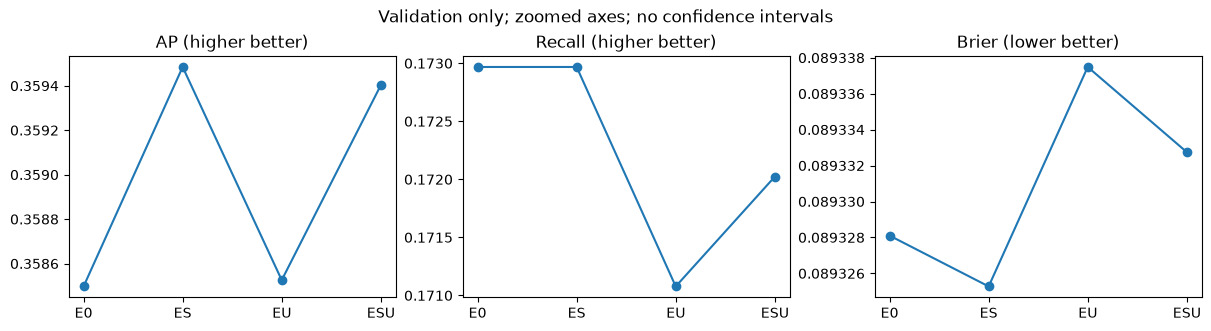

In [17]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,3,figsize=(12,3.2),layout='constrained')
for ax,metric in zip(axes,['AP','Recall','Brier']):
    ax.plot(validation.experiment,validation[metric],marker='o')
    ax.set_title(metric+(' (lower better)' if metric=='Brier' else ' (higher better)'))
    ax.ticklabel_format(axis='y',style='plain',useOffset=False)
fig.suptitle('Validation only; zoomed axes; no confidence intervals')
plt.show()


## 9. Interpretation and limits

S increases overall AP by about 0.00099 (U off) or 0.00088 (U on), with very small Brier changes. U has mixed AP effects and slightly worse Brier under both S settings. ESU-E0: AP +0.000905, Recall -0.0945 percentage points, F1 -0.001306, Brier +0.00000465. These are small descriptive changes, with no significance claim.

At age>=60, ESU identifies 28/128 positives vs E0’s 29/128: recall drops 0.78125 percentage points. Unknown-information Brier worsens by 0.00012293 while recall stays 10/46. Overall AP can improve while some groups incur a cost. None of the displayed validation groups triggers the manual’s small-sample warning, which does not establish statistical precision.

Possible redundancy with previous/poutcome awaits B’s train-only evidence. S changes representation, feature count and regularization geometry. Brier is not a stand-alone calibration test. No causal, discrimination, customer-independent, time-generalization or financial-return claim. Retaining unknown does not automatically improve performance. A semantics improvement can remain defensible even if scores barely change.

## 10. Final-test status and handoff

**Not executed.** C source and tests have been received and locally verified. B’s training-only discovery tables and group/interpretation confirmation are still absent. Human review is pending. See notes/D_MISSING_ITEMS.md. After receiving and reviewing the missing evidence, fill the real handoff receipt, freeze, then run scripts/run_d.py test once. Final fits must use 36,168 train+val rows; test contains 9,043 rows. Do not copy validation scores into test columns. All four test settings and all planned contrasts must be reported.

In [18]:
final_test_status = {'test_evaluated': False, 'C_code': 'received_and_locally_verified', 'B_discovery': 'not_received', 'human_review': 'pending'}
print(final_test_status)

{'test_evaluated': False, 'C_code': 'received_and_locally_verified', 'B_discovery': 'not_received', 'human_review': 'pending'}


## 11. GenAI and contribution declaration

User identifies LIANG SHUANG as D. A owns the data foundation; C supplied the formal pipeline, tests and C chapter; D owns evaluation and this integration. OpenAI Codex assisted with code review, integration, experiment execution, metric checks, figures and explanation drafts. B’s evidence, actual human understanding/review, the four-person video and course submission remain incomplete. No human review is claimed on anyone’s behalf.

Sources: user-supplied C_Pipeline(1).zip (hash in outputs/C/local_integration.json); local execution manual pp6–10; [A repository](https://github.com/raederhans/ca6003-bank-marketing) commit b4c4ff1be75a6e48baacd920f405982b20399352; [UCI](https://archive.ics.uci.edu/dataset/222/bank+marketing); [AP](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.average_precision_score.html); [Brier](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.brier_score_loss.html); [fit boundaries](https://scikit-learn.org/1.8/common_pitfalls.html).

## 06 / 全组封版待办

B补核心发现并复核解释 → 成员实际复核 → D冻结并执行一次最终测试 → 更新所有表图与结论 → C核对单一Notebook → A新内核验收 → 四人连续出镜视频与实际提交。

成员贡献：A数据基础；C正式预处理与14项转换测试；LIANG SHUANG/D统一评价、接入和草稿组织；B证据未收到、不得宣称完成。GenAI辅助范围和实际人工核验状态须由成员补充确认。当前无任何最终测试指标，不能提交成完整作业。